# Improvement needed

As noted in the other python notebook in l3_notes, the problem that we had along the way is that we do not know we are overfitting or not, and the fundamental reason is that we use the same dataset to train the model and to test the model, and therefore, we do not know the loss function outside the dataset used for training. 

In order to solve that problem, we just need to use different dataset for training and testing. Therefore, we can split the whole dataset. The traditional practice is to split the dataset into three parts: train(tr), development(dev)/validation(val), test(ts). 

We rarely touch the test dataset since one can consider the test as "pollution source": once we touch it, there is the risk of overfitting, so we usually work with only the other two. 

The necessity for the existence of dev datasetis that we need to know how the model perform with different hyperparameters (ex. learning rate, batch size). And since we do not want to use test dataset, we often just use the dev dataset to tune those hyperparameters and decide which value works the best. 

# Preparation

In [5]:
import torch
import math
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

words = open('../names.txt', 'r').read().splitlines()
words[:10]

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

block_size = 3 
X, Y = [], []
for word in words:
    context = [0] * block_size 
    for ch in word + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        context = context[1:] + [ix] 
X = torch.tensor(X) 
Y = torch.tensor(Y) 

# Split tr/dev/ts

In [6]:
# build the dataset

def build_dataset(words):
    block_size = 3
    X, Y = [], [] 
    for word in words:
        # print(word)
        context = [0] * block_size 
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '------>', itos[ix])
            context = context[1:] + [ix] 
    X = torch.tensor(X) 
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1: n2])
Xts, Yts = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


# Implementation of Model

Now at this stage, we want to increase the power of the model (namely the number of parameters). 

For example, the embedded vector now only has the size of 2, and maybe that is not enough. In a normal GPT predicted on word level, each word has an embedded vector o size 300. So for this model working on charcter level, we will give each character an embedded vector of size 10. 

At the same time, we will increase the number of neuronsin the hidden layer from 100 to 200. 

Another change we will make here is that we will gradually decrease the value of lr so that the model can converge. 

Another discovery is that after decreasing the learning rate to a very small value, we can iterate from the initial learning rate again, i call this meta stage. 

Caution: if there are too many parameters in the model, the model can easily fit itself to overfit the train dataset, so we do not want to give the model too many parameters either. 

In [60]:
# initialization of the parameters
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator = g) # this is now 30 = 10 * block_size
b1 = torch.randn(200, generator = g)
W2 = torch.randn((200, 27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]
n_para = sum(p.nelement() for p in parameters)
for p in parameters:
    p.requires_grad = True
n_para

11897

tensor(2.1188, grad_fn=<NllLossBackward0>)


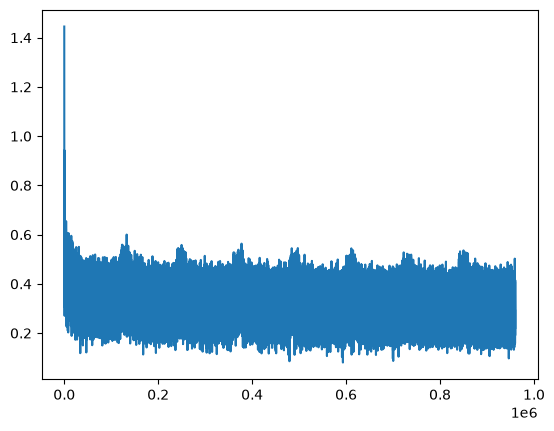

In [ ]:
stepi = []
lossi_log = []

for metastage in range(6):
    metastage_displacement = metastage * 120000
    for stage in range(6):
        lr = 0.13 / (math.sqrt(10) ** stage)
        stage_displacement = stage * 20000
        for i in range(20000):
            # construction of mini batch of size 32
            ix = torch.randint(0, Xtr.shape[0], (32,), generator = g)

            # forward pass
            h = torch.tanh(C[Xtr[ix]].view(-1, 30) @ W1 + b1)
            loss = F.cross_entropy(h @ W2 + b2, Ytr[ix])

            # record the current loss function value
            stepi.append(i+1 + stage_displacement + metastage_displacement)
            lossi_log.append(loss.log10().item())

            # back propogation
            for parameter in parameters:
                parameter.grad = None
            loss.backward()

            # update
            for parameter in parameters:
                parameter.data -= parameter.grad * lr

plt.plot(stepi, lossi_log)
loss = F.cross_entropy(torch.tanh(C[Xdev].view(-1, 30) @ W1 + b1) @ W2 + b2, Ydev)
print(loss)

# Actual result

In [59]:
# sample from the model

g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1) # take exponents and then normalizing
        ix = torch.multinomial(probs, num_samples = 1, generator = g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[ix] for ix in out))


carmah.
ambrilli.
kimri.
reety.
skarshaeja.
hubadamerynci.
aquil.
ramara.
chaiiv.
kaleigh.
ham.
join.
quinn.
shon.
wal.
adbi.
wanelo.
dearynix.
kael.
dus.
